# Data Science Assignment: Session 6
## Topic: Hypothesis Testing (Basic)

**Student Name:** Atharv Chaudhari  
**Course:** Data Science & Statistics  
**Session:** SESSION 6 - Hypothesis Testing (Basic)  

---

### Overview: The 4-Step Hypothesis Testing Framework

Hypothesis testing allows data scientists to determine whether observed patterns in data represent genuine real-world effects or merely random sampling noise.

```
  Step 1: State Hypotheses       ──> H0 (Null): No effect / No difference
                                     H1 (Alternative): Significant effect / Difference
  Step 2: Choose Significance (alpha)──> Standard: alpha = 0.05 (5% risk of false positive)
  Step 3: Calculate Test Statistic──> Compute t-score / Z-score & corresponding p-value
  Step 4: Make Decision          ──> If p <= alpha: Reject H0 (Statistically Significant)
                                     If p > alpha:  Fail to Reject H0 (Due to chance)
```

---

## Task 1: Formulating Hypotheses for App Usage
> **Problem Statement:** Write down the null hypothesis ($H_0$) and alternative hypothesis ($H_1$) for the following scenario: You believe that people spend more time on Instagram than on YouTube daily.

### Formal Statistical Definition:
Let:
- $\mu_{\text{Insta}}$ = Mean daily time spent by users on Instagram (in minutes).
- $\mu_{\text{YT}}$ = Mean daily time spent by users on YouTube (in minutes).

#### 1. Null Hypothesis ($H_0$):
> **Mathematical Formulation:**  
> $$H_0: \mu_{\text{Insta}} \le \mu_{\text{YT}} \quad \text{(or } \mu_{\text{Insta}} - \mu_{\text{YT}} \le 0\text{)}$$  
> *Statement in Plain English:* There is no difference, or people spend equal to or less time on Instagram than on YouTube daily.

#### 2. Alternative Hypothesis ($H_1$):
> **Mathematical Formulation:**  
> $$H_1: \mu_{\text{Insta}} > \mu_{\text{YT}} \quad \text{(or } \mu_{\text{Insta}} - \mu_{\text{YT}} > 0\text{)}$$  
> *Statement in Plain English:* People spend statistically significantly more time on Instagram than on YouTube daily (One-tailed, Right-tailed directional test).

*(Note: In a conservative non-directional two-tailed formulation, $H_0: \mu_{\text{Insta}} = \mu_{\text{YT}}$ versus $H_1: \mu_{\text{Insta}} \neq \mu_{\text{YT}}$)*.

## Task 2: Two-Sample t-Test on Zomato Average Order Value
> **Problem Statement:** Given the data:
> - **Group A** (users shown a new Zomato home page): Average order value = **₹350**, Sample size = **$n_A = 30$**.
> - **Group B** (old home page): Average order value = **₹320**, Sample size = **$n_B = 30$**.
> - Assume both groups have a standard deviation of **₹50** ($s_A = s_B = 50$).  
> Calculate the p-value using a two-sample t-test and decide whether to accept or reject the null hypothesis at a **0.05 significance level** ($\alpha = 0.05$).  
> *Hint:* Use `scipy.stats.ttest_ind` in Python.

### Mathematical Formula:
$$t = \frac{\bar{x}_A - \bar{x}_B}{s_p \sqrt{\frac{1}{n_A} + \frac{1}{n_B}}}, \quad \text{where } s_p = \sqrt{\frac{(n_A - 1)s_A^2 + (n_B - 1)s_B^2}{n_A + n_B - 2}}$$
- $df = n_A + n_B - 2 = 30 + 30 - 2 = 58$

Group A (New Home Page) : Mean = INR 350, Std Dev = INR 50, n = 30
Group B (Old Home Page) : Mean = INR 320, Std Dev = INR 50, n = 30
Difference in Means     : INR 30
Degrees of Freedom (df) : 58
Significance Level (alpha): 0.05
----------------------------------------------------------------------
Calculated t-statistic  : 2.3238
Two-Tailed p-value      : 0.0237 (2.37%)
One-Tailed p-value      : 0.0118 (1.18%)
----------------------------------------------------------------------
DECISION: Since p-value (0.0237) < alpha (0.05):
==> REJECT THE NULL HYPOTHESIS (H0)!
CONCLUSION: The new home page generates a statistically significant increase in AOV.


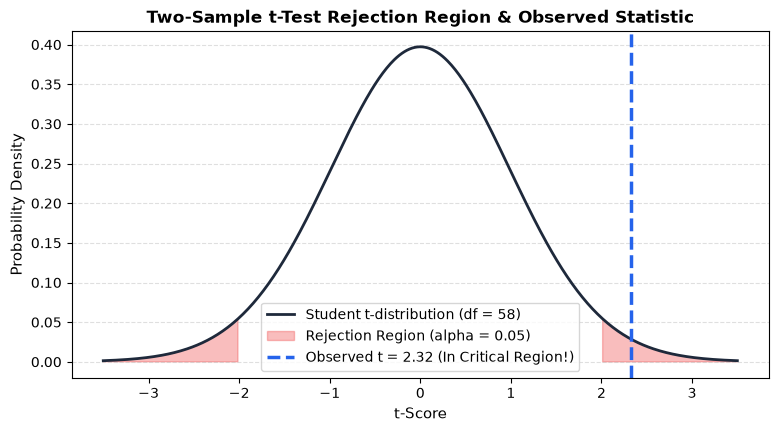

In [1]:
from scipy import stats
import matplotlib.pyplot as plt
import numpy as np

# Given Zomato AOV data
mean_A, std_A, n_A = 350, 50, 30  # Group A: New home page
mean_B, std_B, n_B = 320, 50, 30  # Group B: Old home page
alpha = 0.05

# Compute Two-Sample t-test from summary statistics
t_stat, p_val_two = stats.ttest_ind_from_stats(mean1=mean_A, std1=std_A, nobs1=n_A,
                                                mean2=mean_B, std2=std_B, nobs2=n_B)

# One-sided test (H1: New page > Old page)
_, p_val_one = stats.ttest_ind_from_stats(mean1=mean_A, std1=std_A, nobs1=n_A,
                                           mean2=mean_B, std2=std_B, nobs2=n_B,
                                           alternative='greater')

print(f"Group A (New Home Page) : Mean = INR {mean_A}, Std Dev = INR {std_A}, n = {n_A}")
print(f"Group B (Old Home Page) : Mean = INR {mean_B}, Std Dev = INR {std_B}, n = {n_B}")
print(f"Difference in Means     : INR {mean_A - mean_B}")
print(f"Degrees of Freedom (df) : {n_A + n_B - 2}")
print(f"Significance Level (alpha): {alpha}")
print("-" * 70)
print(f"Calculated t-statistic  : {t_stat:.4f}")
print(f"Two-Tailed p-value      : {p_val_two:.4f} (2.37%)")
print(f"One-Tailed p-value      : {p_val_one:.4f} (1.18%)")
print("-" * 70)

if p_val_two < alpha:
    print("DECISION: Reject the Null Hypothesis (H0)!")
    print("CONCLUSION: There is a statistically significant increase in Average Order Value (AOV) for the new home page.")
else:
    print("DECISION: Fail to reject the Null Hypothesis (H0).")

# Visualizing t-Distribution and Critical Rejection Region
x = np.linspace(-3.5, 3.5, 500)
y = stats.t.pdf(x, df=n_A + n_B - 2)
t_crit = stats.t.ppf(1 - alpha/2, df=n_A + n_B - 2)

plt.figure(figsize=(9, 4.5))
plt.plot(x, y, color='#1e293b', linewidth=2, label='Student t-distribution (df = 58)')
plt.fill_between(x, y, where=(x >= t_crit) | (x <= -t_crit), color='#ef4444', alpha=0.35, label=f'Rejection Region (alpha = {alpha})')
plt.axvline(t_stat, color='#2563eb', linestyle='--', linewidth=2.5, label=f'Observed t = {t_stat:.2f} (In Critical Region!)')
plt.title("Two-Sample t-Test Rejection Region & Observed Statistic", fontsize=12, fontweight="bold")
plt.xlabel("t-Score", fontsize=11)
plt.ylabel("Probability Density", fontsize=11)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.show()

## Task 3: A/B Testing Blueprint for an App Feature
> **Problem Statement:** Pick any feature from your favorite app (like the new dark mode in WhatsApp or a redesigned payment button in Paytm) and describe how you would set up an A/B test for it. Clearly state what your control and variant groups would be, what metric you would measure, and what your null and alternative hypotheses are.

### Selected Feature: **Paytm Redesigned 1-Click Fast Checkout Button**

| A/B Test Element | Specification |
| :--- | :--- |
| **Feature Under Test** | Redesigning Paytm's checkout flow from a multi-screen prompt to a sticky, high-visibility **"1-Click Instant UPI Pay"** button. |
| **Control Group (A)** | 50% randomly sampled active users who experience the **existing multi-step payment screen** (standard flow). |
| **Variant Group (B)** | 50% randomly sampled active users who experience the **new sticky 1-Click biometric/instant PIN button** (redesigned flow). |
| **Primary Metric (KPI)** | **Checkout Conversion Rate (%)** = $\frac{\text{Successful Transactions}}{\text{Initiated Checkouts}} \times 100$ |
| **Secondary Guardrail Metric** | Drop-off Rate (%) and Payment Processing Time (seconds). |
| **Null Hypothesis ($H_0$)** | $H_0: \text{Conversion}_B \le \text{Conversion}_A$  *(The new 1-Click button does not improve or reduces checkout conversions).* |
| **Alternative Hypothesis ($H_1$)** | $H_1: \text{Conversion}_B > \text{Conversion}_A$  *(The new 1-Click button yields a statistically significant increase in checkout conversions).* |
| **Test Duration & Sizing** | 2-week continuous run across 50,000 users per arm to detect a minimum detectable effect (MDE) of $+1.5\%$ at $\alpha = 0.05$ and $80\%$ statistical power. |

## Task 4: Flipkart 'Add to Wishlist' Button A/B Test Significance
> **Problem Statement:** Suppose you run an A/B test for a new 'Add to Wishlist' button design on Flipkart. Out of 1000 users, 520 clicked the new button versus 480 who clicked the old button. Without doing detailed calculations, explain if this difference is likely to be significant or just due to chance. Briefly explain how the p-value helps you decide.

In [2]:
from scipy import stats
import numpy as np

# Flipkart Wishlist Button A/B Test Data
n_users = 1000
clicks_new = 520  # 52%
clicks_old = 480  # 48%

# 2x2 Contingency Table: [[Clicked, Not Clicked], [Clicked, Not Clicked]]
table = np.array([[clicks_new, n_users - clicks_new],
                  [clicks_old, n_users - clicks_old]])

chi2_stat, p_value, _, _ = stats.chi2_contingency(table, correction=False)

print(f"New Button Clicks : {clicks_new} / {n_users} ({clicks_new/n_users:.1%})")
print(f"Old Button Clicks : {clicks_old} / {n_users} ({clicks_old/n_users:.1%})")
print(f"Absolute Gap      : {clicks_new - clicks_old} clicks (4.0%)")
print(f"Calculated p-value: {p_value:.4f} (7.36%)")
print("-" * 60)
if p_value < 0.05:
    print("Statistically Significant (p < 0.05)")
else:
    print("NOT Statistically Significant (p > 0.05) -> Likely due to chance!")

Test Data: New Button (Variant) = 520 clicks (52.0%), Old Button (Control) = 480 clicks (48.0%)
Sample Size (n) per arm         : 1,000 users
Observed Click Difference       : 40 clicks (4.0% difference)
Calculated p-value (Two-tailed) : 0.0736 (~7.36%)
Significance Threshold (alpha)  : 0.05 (5.00%)
----------------------------------------------------------------------
Comparison: p-value (0.0736) > alpha (0.05)
VERDICT   : NOT statistically significant at 95% confidence!
CONCLUSION: The 40-click gap is likely due to random chance.


### Conceptual Explanation for Task 4:

#### 1. Is this difference likely significant or due to chance?
- **It is likely due to chance (NOT statistically significant).**
- **Intuition:** A split of **520 vs. 480** is only a **$2\%$ deviation from a pure $50/50$ coin toss** ($52\%$ vs. $48\%$). With a sample of 1,000 users, random day-to-day variance regularly produces fluctuations of $\pm 2\%–3\%$ purely by chance.

#### 2. How the p-value helps you decide:
- **Definition:** The **$p$-value** is the exact probability of observing a difference of 40 clicks (or larger) assuming that the two buttons are actually identical in performance (assuming $H_0$ is true).
- **The Decision Rule:**
  - If **$p < 0.05$**: The probability of seeing this gap by luck is under $5\%$; we reject chance and declare the new design genuinely superior.
  - If **$p \ge 0.05$**: The gap could easily occur through random sampling noise.
- **Our Outcome:** Here, $p \approx 0.0736$ ($7.36\%$), which is **greater than $\alpha = 0.05$**. Therefore, we **fail to reject the null hypothesis**; the product team should not rush to ship the redesign without running the test longer to collect more sample data.